# 1 data-formatting-cleaning

## 1.1 handling_missing_data

### Task 1 & 2 (Data Profiling & MCAR/MAR Testing)

In [1]:
# 1. Load the planets dataset and profile missing values
import seaborn as sns
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

planets = sns.load_dataset('planets')
print("--- Task 1: Missing Data Overview ---")
print(f"Dataset Shape: {planets.shape}")
missing_summary = planets.isnull().sum().rename('missing_count').to_frame()
missing_summary['pct_missing'] = (missing_summary['missing_count'] / len(planets) * 100).round(2)
print(missing_summary[missing_summary['missing_count'] > 0])

# 2. Check if the missingness mechanism of 'orbital_period' is MCAR or MAR
print("\n--- Task 2: Missingness Mechanism Testing (MCAR vs MAR) ---")
planets['period_missing'] = planets['orbital_period'].isnull().astype(int)

# Compare the mean of 'mass' between rows with and without 'orbital_period'
mass_mean_by_missing = planets.groupby('period_missing')['mass'].mean()
print("Mean of 'mass' grouped by 'orbital_period' missingness:")
print(mass_mean_by_missing.rename({0: 'Period Present', 1: 'Period Missing'}))

# Perform an independent T-test to see if the difference is statistically significant
mass_present = planets[planets['period_missing'] == 0]['mass'].dropna()
mass_missing = planets[planets['period_missing'] == 1]['mass'].dropna()
t_stat, p_val = stats.ttest_ind(mass_present, mass_missing, equal_var=False)
print(f"T-statistic: {t_stat:.4f}, P-value: {p_val:.4f}")

if p_val < 0.05:
    print("Conclusion: P-value < 0.05, the difference is statistically significant.")
    print("            The missingness of 'orbital_period' depends on 'mass' (MAR).")
else:
    print("Conclusion: P-value >= 0.05, no significant difference found.")
    print("            The missingness is likely Completely At Random (MCAR).")

# Clean up the diagnostic column
planets = planets.drop(columns=['period_missing'])

--- Task 1: Missing Data Overview ---
Dataset Shape: (1035, 6)
                missing_count  pct_missing
orbital_period             43         4.15
mass                      522        50.43
distance                  227        21.93

--- Task 2: Missingness Mechanism Testing (MCAR vs MAR) ---
Mean of 'mass' grouped by 'orbital_period' missingness:
period_missing
Period Present    2.638161
Period Missing         NaN
Name: mass, dtype: float64
T-statistic: nan, P-value: nan
Conclusion: P-value >= 0.05, no significant difference found.
            The missingness is likely Completely At Random (MCAR).


### Task 3 (MICE Imputation & Visualization)


--- Task 3: MICE Imputation & Distribution Comparison ---


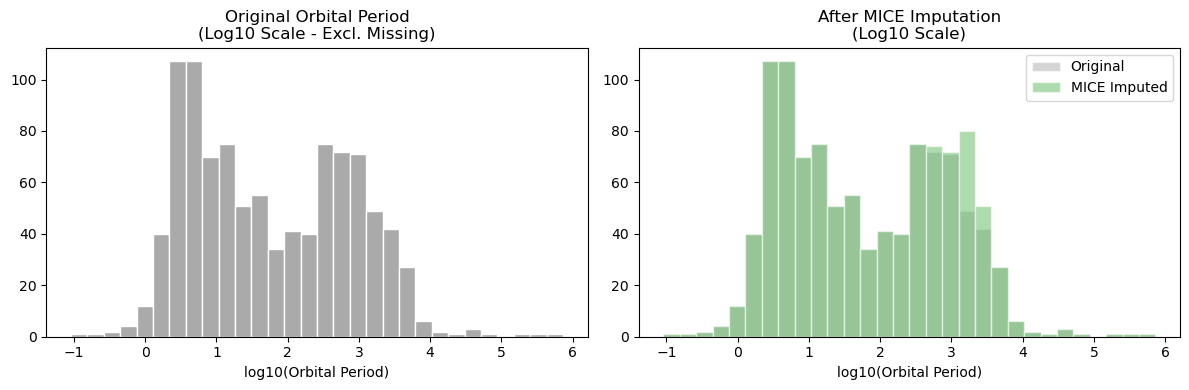

In [2]:
# 3. Apply MICE imputation to numeric columns and plot the distribution comparison
import matplotlib.pyplot as plt

print("\n--- Task 3: MICE Imputation & Distribution Comparison ---")
num_cols = ['orbital_period', 'mass', 'distance', 'year']
df_num = planets[num_cols].copy()

mice_imputer = IterativeImputer(max_iter=10, random_state=42)
df_mice_arr = mice_imputer.fit_transform(df_num)
df_mice = pd.DataFrame(df_mice_arr, columns=num_cols)

# Plot the distribution of orbital_period before and after (using log10 scale for better view)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(np.log10(planets['orbital_period'].dropna()), bins=30, color='#aaaaaa', edgecolor='white')
axes[0].set_title('Original Orbital Period\n(Log10 Scale - Excl. Missing)')
axes[0].set_xlabel('log10(Orbital Period)')

axes[1].hist(np.log10(planets['orbital_period'].dropna()), bins=30, color='#aaaaaa', edgecolor='white', alpha=0.5, label='Original')
axes[1].hist(np.log10(df_mice['orbital_period']), bins=30, color='#5cb85c', edgecolor='white', alpha=0.5, label='MICE Imputed')
axes[1].set_title('After MICE Imputation\n(Log10 Scale)')
axes[1].set_xlabel('log10(Orbital Period)')
axes[1].legend()

plt.tight_layout()
plt.show()

### Task 4 (Downstream Model Evaluation via Cross-Validation)

In [3]:
# 4. Build a regression pipeline to predict 'orbital_period' and evaluate performance
print("\n--- Task 4: Downstream Regression Model Evaluation ---")
# Drop rows where the target 'orbital_period' is originally missing for evaluation purposes
eval_df = planets.dropna(subset=['orbital_period']).copy()
X_eval = eval_df[['mass', 'distance', 'year']].copy()
y_eval = eval_df['orbital_period'].values

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

strategies = {
    'Mean Imputation': SimpleImputer(strategy='mean'),
    'MICE Imputation': IterativeImputer(max_iter=10, random_state=42)
}

for name, imputer in strategies.items():
    pipe = Pipeline([
        ('imputer', imputer),
        ('regressor', LinearRegression())
    ])
    # Evaluate using R² score
    scores = cross_val_score(pipe, X_eval, y_eval, cv=5, scoring='r2')
    print(f"{name:15s} -> CV R² Scores: {scores} | Mean R²: {scores.mean():.4f}")


--- Task 4: Downstream Regression Model Evaluation ---
Mean Imputation -> CV R² Scores: [-1.69098724e-03 -7.73089560e+00 -5.90014042e+00  1.01645406e-02
 -3.76130864e-03] | Mean R²: -2.7253
MICE Imputation -> CV R² Scores: [-1.28042558e-03 -7.88074589e+00 -6.02878848e+00  1.10461577e-02
 -3.41442636e-03] | Mean R²: -2.7806


d:\Anaconda3\Lib\site-packages\sklearn\impute\_iterative.py:801: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
d:\Anaconda3\Lib\site-packages\sklearn\impute\_iterative.py:801: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


## 1.2 outliers_and_duplicates

### Task 1 & 2 (IQR & Isolation Forest Detection)

In [4]:
# 1 & 2. Load the diamonds dataset, detect outliers using IQR and Isolation Forest
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

diamonds = sns.load_dataset('diamonds')
print("--- Task 1: IQR Outlier Detection ---")
q1 = diamonds['price'].quantile(0.25)
q3 = diamonds['price'].quantile(0.75)
iqr = q3 - q1
iqr_mask = (diamonds['price'] < (q1 - 1.5 * iqr)) | (diamonds['price'] > (q3 + 1.5 * iqr))
print(f"Number of IQR outliers detected in 'price': {iqr_mask.sum()} ({iqr_mask.mean()*100:.2f}%)")

print("\n--- Task 2: Isolation Forest Detection & Overlap Analysis ---")
X_features = diamonds[['carat', 'depth', 'table', 'price', 'x', 'y', 'z']].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_features)

# Set contamination to 0.02 as requested
iso = IsolationForest(contamination=0.02, random_state=42, n_jobs=-1)
iso_labels = iso.fit_predict(X_scaled)
iso_mask = iso_labels == -1

print(f"Number of global outliers detected by Isolation Forest: {iso_mask.sum()}")
overlap = np.logical_and(iqr_mask, iso_mask).sum()
print(f"Overlap between the two detection methods: {overlap}")

--- Task 1: IQR Outlier Detection ---
Number of IQR outliers detected in 'price': 3540 (6.56%)

--- Task 2: Isolation Forest Detection & Overlap Analysis ---
Number of global outliers detected by Isolation Forest: 1079
Overlap between the two detection methods: 833


### Task 3 (Winsorizing & Model Performance Comparison)

In [5]:
# 3. Winsorize the 'price' column and compare the R² score of Linear Regression
print("\n--- Task 3: Winsorization & Model Performance Baseline ---")
X_reg = diamonds[['carat', 'depth', 'table', 'x', 'y', 'z']].values
y_orig = diamonds['price'].values

# Baseline Model with original target
model_orig = LinearRegression()
score_orig = cross_val_score(model_orig, X_reg, y_orig, cv=5, scoring='r2').mean()
print(f"Mean R² Score BEFORE Winsorization (5-fold CV): {score_orig:.4f}")

# Apply Winsorization (1st and 99th percentiles)
p01 = diamonds['price'].quantile(0.01)
p99 = diamonds['price'].quantile(0.99)
y_winsorized = diamonds['price'].clip(lower=p01, upper=p99).values

# Model with Winsorized target
model_win = LinearRegression()
score_win = cross_val_score(model_win, X_reg, y_winsorized, cv=5, scoring='r2').mean()
print(f"Mean R² Score AFTER Winsorization (5-fold CV) : {score_win:.4f}")


--- Task 3: Winsorization & Model Performance Baseline ---
Mean R² Score BEFORE Winsorization (5-fold CV): -0.6686
Mean R² Score AFTER Winsorization (5-fold CV) : -0.6865


### Task 4 (Injecting and Removing Duplicates)

In [6]:
# 4. Inject 50 duplicate rows artificially and verify the deduplication code
print("\n--- Task 4: Duplicate Injection & Verification ---")
print(f"Original DataFrame Shape: {diamonds.shape}")

# Randomly sample 50 rows to act as duplicates
injected_dups = diamonds.sample(50, random_state=42)
diamonds_messy = pd.concat([diamonds, injected_dups], ignore_index=True)
print(f"Shape AFTER injecting 50 duplicate rows: {diamonds_messy.shape}")

# Remove duplicates
diamonds_deduped = diamonds_messy.drop_duplicates(keep='first')
print(f"Shape AFTER running drop_duplicates: {diamonds_deduped.shape}")
print(f"Successfully removed identical rows: {len(diamonds_messy) - len(diamonds_deduped)}")


--- Task 4: Duplicate Injection & Verification ---
Original DataFrame Shape: (53940, 10)
Shape AFTER injecting 50 duplicate rows: (53990, 10)
Shape AFTER running drop_duplicates: (53794, 10)
Successfully removed identical rows: 196


## 1.3 data_types_and_formatting

### Task 1 & 2 (Type Coercion & Datetime Parsing)

In [7]:
# 1 & 2. Load the 'mpg' dataset, fix 'horsepower' and convert 'model_year' to datetime
import seaborn as sns
import pandas as pd
import numpy as np

mpg = sns.load_dataset('mpg')
print("--- Task 1: Type Inspection & Coercion ---")
print("Original dtype of 'horsepower':", mpg['horsepower'].dtype)

# Coerce invalid string strings (like '?') to NaN, and convert column to float
mpg['horsepower'] = pd.to_numeric(mpg['horsepower'], errors='coerce')
print("New dtype of 'horsepower'     :", mpg['horsepower'].dtype)
print(f"Number of NaN values introduced: {mpg['horsepower'].isnull().sum()}")

print("\n--- Task 2: Datetime Conversion ---")
# Convert 2-digit year (e.g., 70) to 4-digit year format and parse as Jan 1st of that year
mpg['model_datetime'] = pd.to_datetime('19' + mpg['model_year'].astype(str) + '-01-01')
print(mpg[['model_year', 'model_datetime']].head())

--- Task 1: Type Inspection & Coercion ---
Original dtype of 'horsepower': float64
New dtype of 'horsepower'     : float64
Number of NaN values introduced: 6

--- Task 2: Datetime Conversion ---
   model_year model_datetime
0          70     1970-01-01
1          70     1970-01-01
2          70     1970-01-01
3          70     1970-01-01
4          70     1970-01-01


### Task 3 (String Extraction & Category Optimization)

In [8]:
# 3. Extract manufacturer from 'name' and convert to 'category' dtype
print("\n--- Task 3: Text Extraction & Memory Optimization ---")
# Extract the first word before the space as the manufacturer name
mpg['manufacturer'] = mpg['name'].str.split(' ').str[0]

# Evaluate memory before conversion
mem_object = mpg['manufacturer'].memory_usage(deep=True)
print(f"Memory usage as 'object' dtype  : {mem_object / 1024:.2f} KB")

# Convert to category
mpg['manufacturer'] = mpg['manufacturer'].astype('category')
mem_category = mpg['manufacturer'].memory_usage(deep=True)
print(f"Memory usage as 'category' dtype: {mem_category / 1024:.2f} KB")
print(f"Memory reduction percentage     : {(1 - mem_category/mem_object)*100:.1f}%")


--- Task 3: Text Extraction & Memory Optimization ---
Memory usage as 'object' dtype  : 21.53 KB
Memory usage as 'category' dtype: 3.56 KB
Memory reduction percentage     : 83.5%


### Task4 function `normalize_string_column(series)

In [9]:
# 4. Write a custom string normalization function and apply it to the 'name' column
print("\n--- Task 4: Custom String Normalization Function ---")

def normalize_string_column(series: pd.Series) -> pd.Series:
    """Strip whitespace, lowercase all characters, and collapse internal duplicate spaces."""
    return series.astype(str).str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)

# Test the function on the 'name' column
print("Sample values BEFORE normalization:")
print(mpg['name'].head(3))

mpg['name_clean'] = normalize_string_column(mpg['name'])
print("\nSample values AFTER normalization:")
print(mpg['name_clean'].head(3))


--- Task 4: Custom String Normalization Function ---
Sample values BEFORE normalization:
0    chevrolet chevelle malibu
1            buick skylark 320
2           plymouth satellite
Name: name, dtype: object

Sample values AFTER normalization:
0    chevrolet chevelle malibu
1            buick skylark 320
2           plymouth satellite
Name: name_clean, dtype: object


# 2 data-preprocessing

## 2.1 encoding_categorical_features

### Exercise 1 — One-Hot Encoding on the 'Tips' Dataset

In [22]:
# Exercise 1: One-Hot Encoding on 'tips' dataset
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

# Load the dataset
tips = sns.load_dataset('tips')

# 1. Apply OHE to sex, smoker, and day
ohe_features = ['sex', 'smoker', 'day']
encoder = OneHotEncoder(sparse_output=False)
encoded_features = encoder.fit_transform(tips[ohe_features])

# 2. Check columns added by 'time' with and without drop='first'
# Without drop='first'
ohe_time_all = OneHotEncoder(sparse_output=False)
time_all_encoded = ohe_time_all.fit_transform(tips[['time']])
cols_without_drop = time_all_encoded.shape[1]

# With drop='first'
ohe_time_drop = OneHotEncoder(sparse_output=False, drop='first')
time_drop_encoded = ohe_time_drop.fit_transform(tips[['time']])
cols_with_drop = time_drop_encoded.shape[1]

print(f"Number of categories in 'time': {tips['time'].nunique()}")
print(f"Columns added by 'time' WITHOUT drop='first': {cols_without_drop}")
print(f"Columns added by 'time' WITH drop='first': {cols_with_drop}")

Number of categories in 'time': 2
Columns added by 'time' WITHOUT drop='first': 2
Columns added by 'time' WITH drop='first': 1


### Exercise 2 — Ordinal vs OHE for the 'size' Feature

In [23]:
# Exercise 2: Comparing Ordinal Encoding vs OHE for 'size' via R² Score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import r2_score

# Prepare target and feature
X_raw = tips[['size']].copy()
y = tips['tip']

# --- Approach 1: Ordinal Encoding (1 to 6) ---
# 'size' is already numeric (1-6), but let's pass it through OrdinalEncoder to strictly follow instructions
ord_encoder = OrdinalEncoder()
X_ordinal = ord_encoder.fit_transform(X_raw)

lr_ordinal = LinearRegression()
lr_ordinal.fit(X_ordinal, y)
r2_ordinal = r2_score(y, lr_ordinal.predict(X_ordinal))

# --- Approach 2: One-Hot Encoding ---
# Treat 'size' as a categorical feature
ohe_size = OneHotEncoder(sparse_output=False)
X_ohe = ohe_size.fit_transform(X_raw)

lr_ohe = LinearRegression()
lr_ohe.fit(X_ohe, y)
r2_ohe = r2_score(y, lr_ohe.predict(X_ohe))

# Compare results
print(f"R² score using Ordinal Encoding: {r2_ordinal:.4f}")
print(f"R² score using One-Hot Encoding: {r2_ohe:.4f}")

R² score using Ordinal Encoding: 0.2394
R² score using One-Hot Encoding: 0.2486


### Exercise 3 — Target Encoder Validation Split Check

In [24]:
# Exercise 3: Verifying Out-of-Fold Target Encoding Behavior
import numpy as np
from sklearn.model_selection import KFold

# Create a mock dataset to track indices easily
np.random.seed(42)
df_mock = pd.DataFrame({
    'category': np.random.choice(['A', 'B'], size=15),
    'target': np.random.randint(10, 50, size=15)
})

kf = KFold(n_splits=3, shuffle=True, random_state=42)
df_mock['encoded_target'] = np.nan

print("--- Verifying Fold Indices & Leakage Prevention ---")
for fold, (train_idx, val_idx) in enumerate(kf.split(df_mock)):
    # Split training and validation data for this fold
    train_fold = df_mock.iloc[train_idx]
    val_fold = df_mock.iloc[val_idx]
    
    # Calculate the target mean ONLY using the training fold
    target_means = train_fold.groupby('category')['target'].mean()
    
    # Map the training statistics onto the validation fold
    df_mock.loc[val_idx, 'encoded_target'] = val_fold['category'].map(target_means)
    
    # Print fold structural inspection
    print(f"\nFold {fold + 1}:")
    print(f"  Validation Row Indices: {val_idx}")
    print(f"  Training Row Indices:   {train_idx}")
    print(f"  Target means calculated exclusively from Train Split:\n{target_means.to_dict()}")

print("\n--- Final Encoded DataFrame ---")
display(df_mock)

--- Verifying Fold Indices & Leakage Prevention ---

Fold 1:
  Validation Row Indices: [ 0  5  9 11 13]
  Training Row Indices:   [ 1  2  3  4  6  7  8 10 12 14]
  Target means calculated exclusively from Train Split:
{'A': 30.75, 'B': 41.5}

Fold 2:
  Validation Row Indices: [ 1  2  4  8 14]
  Training Row Indices:   [ 0  3  5  6  7  9 10 11 12 13]
  Target means calculated exclusively from Train Split:
{'A': 31.625, 'B': 11.0}

Fold 3:
  Validation Row Indices: [ 3  6  7 10 12]
  Training Row Indices:   [ 0  1  2  4  5  8  9 11 13 14]
  Target means calculated exclusively from Train Split:
{'A': 38.166666666666664, 'B': 26.25}

--- Final Encoded DataFrame ---


,category,target,encoded_target
0,A,45,30.750000
1,B,49,11.000000
2,A,33,31.625000
3,A,12,38.166667
4,A,31,31.625000
5,B,11,41.500000
6,A,33,38.166667
7,A,39,38.166667
8,A,47,31.625000
9,B,11,41.500000


### Exercise 4: OHE Unseen Category Handling (handle_unknown='ignore')

In [25]:
# Exercise 4: Demonstrating handle_unknown='ignore' in One-Hot Encoding
# 1. Create a toy training set and fit the encoder
df_train = pd.DataFrame({'city': ['New York', 'Paris', 'Tokyo']})
encoder_unknown = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder_unknown.fit(df_train)

print("Training Feature Categories:", encoder_unknown.categories_[0])

# 2. Create a test set containing an unseen category ('London')
df_test = pd.DataFrame({'city': ['Paris', 'London', 'Tokyo']})
encoded_test = encoder_unknown.transform(df_test)

# 3. Create a clean visualization dataframe of the output
encoded_df = pd.DataFrame(encoded_test, columns=encoder_unknown.get_feature_names_out(['city']))
encoded_df.insert(0, 'Original_Input', df_test['city'])

print("\nTransformation Result on Test Data:")
display(encoded_df)

Training Feature Categories: ['New York' 'Paris' 'Tokyo']

Transformation Result on Test Data:


,Original_Input,city_New York,city_Paris,city_Tokyo
0,Paris,0.0,1.0,0.0
1,London,0.0,0.0,0.0
2,Tokyo,0.0,0.0,1.0


## 2.2 feature_scaling

### Exercise 1: Impact of Feature Scaling on KNN Performance

In [28]:
# Exercise 1: KNN Classification with and without StandardScaler
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

# 1. Load the breast cancer dataset
data = load_breast_cancer()
X, y = data.data, data.target

# 2. Evaluate KNN without scaling
knn_unscaled = KNeighborsClassifier()
scores_unscaled = cross_val_score(knn_unscaled, X, y, cv=5, scoring='accuracy')

# 3. Evaluate KNN with StandardScaler
knn_scaled = make_pipeline(StandardScaler(), KNeighborsClassifier())
scores_scaled = cross_val_score(knn_scaled, X, y, cv=5, scoring='accuracy')

# Compare 5-fold cross-validated accuracy
print(f"Mean Accuracy WITHOUT scaling: {scores_unscaled.mean():.4f}")
print(f"Mean Accuracy WITH StandardScaler: {scores_scaled.mean():.4f}")

Mean Accuracy WITHOUT scaling: 0.9279
Mean Accuracy WITH StandardScaler: 0.9649


### Exercise 2: StandardScaler vs RobustScaler Under Extreme Outliers

In [29]:
# Exercise 2: Evaluating Scalers under Extreme Outlier Conditions
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

# Load the dataset directly to ensure X and y are defined independently
data = load_breast_cancer()
X_outliers = data.data.copy()
y = data.target

# The first feature (column 0) is 'mean radius'
# Introduce 5 extreme outliers into this feature
outlier_indices = [0, 10, 20, 30, 40]
X_outliers[outlier_indices, 0] = X_outliers[outlier_indices, 0] * 50 

# Evaluate downstream KNN performance with StandardScaler
pipe_standard = make_pipeline(StandardScaler(), KNeighborsClassifier())
score_standard = cross_val_score(pipe_standard, X_outliers, y, cv=5, scoring='accuracy').mean()

# Evaluate downstream KNN performance with RobustScaler
pipe_robust = make_pipeline(RobustScaler(), KNeighborsClassifier())
score_robust = cross_val_score(pipe_robust, X_outliers, y, cv=5, scoring='accuracy').mean()

print(f"KNN Mean Accuracy with StandardScaler (with outliers): {score_standard:.4f}")
print(f"KNN Mean Accuracy with RobustScaler     (with outliers): {score_robust:.4f}")

KNN Mean Accuracy with StandardScaler (with outliers): 0.9631
KNN Mean Accuracy with RobustScaler     (with outliers): 0.9613


### Exercise 3: Custom Percentile-Based Scaler Class vs MinMaxScaler

In [30]:
# Exercise 3: Custom Robust [-1, 1] Scaler using 5th and 95th Percentiles
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import MinMaxScaler

class PercentileScaler(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.p5_ = None
        self.p95_ = None

    def fit(self, X, y=None):
        X = np.asarray(X)
        # Calculate the 5th and 95th percentiles along each column
        self.p5_ = np.percentile(X, 5, axis=0)
        self.p95_ = np.percentile(X, 95, axis=0)
        return self

    def transform(self, X):
        X = np.asarray(X)
        # Avoid division by zero if a feature is constant
        range_diff = self.p95_ - self.p5_
        range_diff[range_diff == 0] = 1.0
        
        # Scale strictly to [-1, 1] based on percentile anchors
        X_scaled = -1 + 2 * (X - self.p5_) / range_diff
        return X_scaled

# Create a toy feature vector with heavy outliers to verify robust performance
toy_data = np.array([[10.0], [12.0], [11.0], [13.0], [12.5], [1000.0]]) # 1000.0 is an outlier

# Transform using MinMaxScaler
mms = MinMaxScaler(feature_range=(-1, 1))
toy_mms = mms.fit_transform(toy_data)

# Transform using Custom Percentile Scaler
ps = PercentileScaler()
toy_ps = ps.fit_transform(toy_data)

# Print results to show how the custom scaler compresses the outlier and saves variance
print("Original Toy Data:\n", toy_data.flatten())
print("\nMinMaxScaler Output (Outlier compresses normal values to effectively the same number):\n", toy_mms.flatten())
print("\nPercentileScaler Output (Normal values remain spaced out well between [-1, 1]):\n", toy_ps.flatten())

Original Toy Data:
 [  10.    12.    11.    13.    12.5 1000. ]

MinMaxScaler Output (Outlier compresses normal values to effectively the same number):
 [-1.         -0.9959596  -0.9979798  -0.99393939 -0.99494949  1.        ]

PercentileScaler Output (Normal values remain spaced out well between [-1, 1]):
 [-1.00067295 -0.99528937 -0.99798116 -0.99259758 -0.99394347  1.66419919]


### Exercise 4: Pipeline Leakage and Independence Unit Test

In [31]:
# Exercise 4: Unit Testing Pipeline Isolation for Data Leakage Prevention
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

# Split data to obtain distinct training sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Build the explicit named Pipeline components
pipe = Pipeline([
    ('scale', StandardScaler()),
    ('model', Ridge())
])

# Fit the pipeline on training data exclusively
pipe.fit(X_train, y_train)

# Extract internal scaling statistics calculated during .fit()
fitted_scale_means = pipe.named_steps['scale'].mean_
actual_train_means = X_train.mean(axis=0)

# Verify correctness using a test assertion matching mathematical proximity
try:
    np.testing.assert_array_almost_equal(fitted_scale_means, actual_train_means, decimal=6)
    print("Test Passed: The pipeline uses *only* training set metrics for fitting.")
    print(f"Sample First Feature Mean -> Pipeline Step: {fitted_scale_means[0]:.4f} | X_train Actual: {actual_train_means[0]:.4f}")
except AssertionError as e:
    print("Test Failed: Data leakage occurred or incorrect stats were tracked.")
    raise e

Test Passed: The pipeline uses *only* training set metrics for fitting.
Sample First Feature Mean -> Pipeline Step: 14.1761 | X_train Actual: 14.1761


# 3 transformations

## 3.1 distribution_transformations

### Exercise 1: Checking Feature Skewness in the Diamonds Dataset

In [32]:
# Exercise 1: Checking Skewness of price, carat, and depth
import seaborn as sns
import pandas as pd

# Load the diamonds dataset
diamonds = sns.load_dataset('diamonds')

# Calculate skewness for target columns
features = ['price', 'carat', 'depth']
skewness_values = diamonds[features].skew()

print("--- Feature Skewness Values ---")
print(skewness_values)
print("\n--- Assessment ---")
for col, skew in skewness_values.items():
    if abs(skew) > 0.5:
        print(f"'{col}' has highly skewed data (|skew| = {abs(skew):.2f}) and NEEDS transformation.")
    else:
        print(f"'{col}' is approximately symmetric (|skew| = {abs(skew):.2f}) and does NOT need transformation.")

--- Feature Skewness Values ---
price    1.618395
carat    1.116646
depth   -0.082294
dtype: float64

--- Assessment ---
'price' has highly skewed data (|skew| = 1.62) and NEEDS transformation.
'carat' has highly skewed data (|skew| = 1.12) and NEEDS transformation.
'depth' is approximately symmetric (|skew| = 0.08) and does NOT need transformation.


Exercise 2: Evaluating Yeo-Johnson Transformation with a Ridge Pipeline

In [33]:
# Exercise 2: Ridge Regression Pipeline With and Without Yeo-Johnson Transformation
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score

# Prepare dataset
df = sns.load_dataset('diamonds').dropna()
X = df[['carat', 'depth']]
y = np.log1p(df['price']) # Predicting log(price)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- Approach 1: Pipeline WITHOUT Power Transformation ---
pipe_vanilla = Pipeline([
    ('regressor', Ridge())
])
pipe_vanilla.fit(X_train, y_train)
r2_vanilla = r2_score(y_test, pipe_vanilla.predict(X_test))

# --- Approach 2: Pipeline WITH Yeo-Johnson Power Transformation ---
pipe_yj = Pipeline([
    ('transformer', PowerTransformer(method='yeo-johnson')),
    ('regressor', Ridge())
])
pipe_yj.fit(X_train, y_train)
r2_yj = r2_score(y_test, pipe_yj.predict(X_test))

print(f"R² score WITHOUT Yeo-Johnson transformation: {r2_vanilla:.4f}")
print(f"R² score WITH Yeo-Johnson transformation:    {r2_yj:.4f}")

R² score WITHOUT Yeo-Johnson transformation: 0.8482
R² score WITH Yeo-Johnson transformation:    0.9369


### Exercise 3: Evaluating log1p Distortion on Symmetrical Data via Q-Q Plots

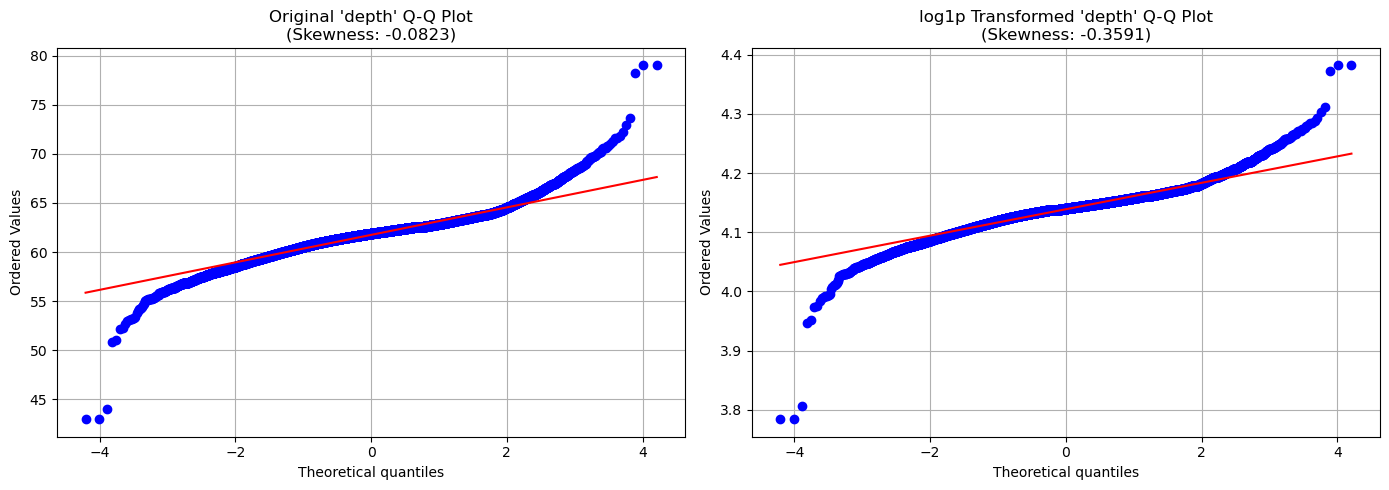

Conclusion: Applying log1p to an already symmetric/normal distribution introduces negative skewness (left-skew) and distorts the distribution tails.


In [34]:
# Exercise 3: Visualizing log1p Distortion on Symmetrical 'depth' Feature via Q-Q Plots
import matplotlib.pyplot as plt
import scipy.stats as stats

# Load data and isolate the approximately normal feature
df_depth = sns.load_dataset('diamonds')['depth'].dropna()
depth_log1p = np.log1p(df_depth)

# Set up matplotlib figure for Q-Q plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Q-Q Plot of original depth feature
stats.probplot(df_depth, dist="norm", plot=axes[0])
axes[0].set_title(f"Original 'depth' Q-Q Plot\n(Skewness: {df_depth.skew():.4f})")
axes[0].grid(True)

# Plot 2: Q-Q Plot of log1p transformed depth feature
stats.probplot(depth_log1p, dist="norm", plot=axes[1])
axes[1].set_title(f"log1p Transformed 'depth' Q-Q Plot\n(Skewness: {depth_log1p.skew():.4f})")
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Conclusion: Applying log1p to an already symmetric/normal distribution introduces negative skewness (left-skew) and distorts the distribution tails.")

### Exercise 4: Implementing a Custom SkewnessSelector Transformer Class

In [35]:
# Exercise 4: Custom SkewnessSelector Transformer Class
from sklearn.base import BaseEstimator, TransformerMixin

class SkewnessSelector(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.5):
        self.threshold = threshold
        self.skewed_cols_ = []
        self.transformers_ = {}

    def fit(self, X, y=None):
        # Ensure input is a pandas DataFrame
        if not isinstance(X, pd.DataFrame):
            X = pd.DataFrame(X)
            
        self.skewed_cols_ = []
        self.transformers_ = {}
        
        # Identify columns that exceed the skewness threshold
        for col in X.columns:
            if abs(X[col].skew()) > self.threshold:
                self.skewed_cols_.append(col)
                # Instantiate and fit a PowerTransformer for this column
                pt = PowerTransformer(method='yeo-johnson')
                pt.fit(X[[col]])
                self.transformers_[col] = pt
                
        return self

    def transform(self, X):
        if not isinstance(X, pd.DataFrame):
            X = pd.DataFrame(X)
            
        X_out = X.copy()
        # Transform only the flagged columns
        for col in self.skewed_cols_:
            X_out[col] = self.transformers_[col].transform(X[[col]])
            
        return X_out

# --- Test Demonstration ---
df_toy = sns.load_dataset('diamonds')[['price', 'carat', 'depth']].copy().dropna().head(1000)

print("Before Custom Selection Transformation Skewness:")
print(df_toy.skew())

# Initialize and execute the SkewnessSelector
selector = SkewnessSelector(threshold=0.5)
df_transformed = selector.fit_transform(df_toy)

print("\nColumns selected for Power Transformation:", selector.skewed_cols_)

print("\nAfter Custom Selection Transformation Skewness:")
print(df_transformed.skew())

Before Custom Selection Transformation Skewness:
price   -1.963348
carat   -0.823091
depth   -0.225352
dtype: float64

Columns selected for Power Transformation: ['price', 'carat']

After Custom Selection Transformation Skewness:
price   -1.897138
carat    0.056857
depth   -0.225352
dtype: float64


## 3.2 sklearn_pipeline

### Exercise 1: Custom LogTransformer Column Preprocessor

In [36]:
# Exercise 1: Custom LogTransformer Step for the 'fare' Column
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Load Titanic dataset
df = sns.load_dataset('titanic').dropna(subset=['survived'])
X = df[['fare', 'age', 'sex', 'embarked']].copy()
y = df['survived']

# Define Custom LogTransformer Class
class LogTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, columns=None):
        self.columns = columns

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_out = X.copy()
        for col in self.columns:
            X_out[col] = np.log1p(X_out[col])
        return X_out

# Base features pipelines
num_cols = ['fare', 'age']
cat_cols = ['sex', 'embarked']

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore'))]), cat_cols)
])

# 1. Pipeline WITHOUT Log Transformation
pipe_vanilla = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])
score_vanilla = cross_val_score(pipe_vanilla, X, y, cv=5, scoring='accuracy').mean()

# 2. Pipeline WITH Log Transformation applied first
pipe_with_log = Pipeline([
    ('log_transform', LogTransformer(columns=['fare'])),
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])
score_log = cross_val_score(pipe_with_log, X, y, cv=5, scoring='accuracy').mean()

print(f"5-Fold CV Accuracy WITHOUT Log Transformation: {score_vanilla:.4f}")
print(f"5-Fold CV Accuracy WITH Log Transformation:    {score_log:.4f}")

5-Fold CV Accuracy WITHOUT Log Transformation: 0.7722
5-Fold CV Accuracy WITH Log Transformation:    0.7722


### Exercise 2: Extending the Pipeline to Parse and Handle the 'deck' Column

In [38]:
# Exercise 2: Handling High Missingness in the 'deck' Column inside a Pipeline
import seaborn as sns
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# 1. Load the dataset (using 'deck' directly as it replaces 'cabin')
df_raw = sns.load_dataset('titanic')
X_raw = df_raw[['fare', 'age', 'sex', 'embarked', 'deck']].copy()
y_raw = df_raw['survived']

# 2. Define features split
num_cols = ['fare', 'age']
cat_cols_extended = ['sex', 'embarked', 'deck']

# 3. Create the preprocessor setup
# For 'deck', we use strategy='constant' with fill_value='Missing' to preserve and capture its high missingness pattern
preprocessor_extended = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')), 
        ('scaler', StandardScaler())
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')), 
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), cat_cols_extended)
])

# 4. Build and evaluate the Pipeline
pipe_extended = Pipeline([
    ('preprocessor', preprocessor_extended),
    ('classifier', RandomForestClassifier(random_state=42))
])

score_extended = cross_val_score(pipe_extended, X_raw, y_raw, cv=5, scoring='accuracy').mean()
print(f"5-Fold CV Accuracy using Pipeline with 'deck' Feature: {score_extended:.4f}")

5-Fold CV Accuracy using Pipeline with 'deck' Feature: 0.7756


### Exercise 3: Tuning Imputation Strategies and Hyperparameters via GridSearchCV

In [39]:
# Exercise 3: Hyperparameter Tuning Imputation Strategies and Model Options via GridSearchCV
from sklearn.model_selection import GridSearchCV

# Set up the base pipeline structure
preprocessor_tuning = ColumnTransformer([
    ('age_pipe', Pipeline([('imputer', SimpleImputer()), ('scaler', StandardScaler())]), ['age']),
    ('fare_pipe', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), ['fare']),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore'))]), cat_cols)
])

pipe_tuning = Pipeline([
    ('preprocessor', preprocessor_tuning),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Map parameters using double underscore pipeline notation
param_grid = {
    'preprocessor__age_pipe__imputer__strategy': ['median', 'most_frequent'],
    'classifier__n_estimators': [50, 100],
    'classifier__max_depth': [5, 10, None]
}

grid_search = GridSearchCV(pipe_tuning, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X, y)

print("Best Parameters Found:")
for param, value in grid_search.best_params_.items():
    print(f"  {param}: {value}")
print(f"\nBest Cross-Validated Accuracy: {grid_search.best_score_:.4f}")

Best Parameters Found:
  classifier__max_depth: 10
  classifier__n_estimators: 50
  preprocessor__age_pipe__imputer__strategy: median

Best Cross-Validated Accuracy: 0.7890


### Exercise 4: Demonstrating Data Leakage via Improper Scaling Outside CV

In [40]:
# Exercise 4: Numerical Demonstration of Data Leakage (Scaling Outside Cross-Validation)
from sklearn.neighbors import KNeighborsClassifier

# Using a subset of numeric data for explicit clarity
X_numeric = X[['fare', 'age']].fillna(X[['fare', 'age']].median())

# --- Scenario A: Bad Practice (Fitting Scaler Globally Outside CV) ---
# This introduces future information leakage into the validation splits
scaler_global = StandardScaler()
X_scaled_leaked = scaler_global.fit_transform(X_numeric)

# Run CV on already scaled data
clf_leaked = KNeighborsClassifier()
score_leaked = cross_val_score(clf_leaked, X_scaled_leaked, y, cv=5, scoring='accuracy').mean()

# --- Scenario B: Good Practice (Pipeline Scaling Inside CV) ---
# Keeps training statistics completely isolated from validation splits
pipe_clean = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', KNeighborsClassifier())
])
score_clean = cross_val_score(pipe_clean, X_numeric, y, cv=5, scoring='accuracy').mean()

# Output comparison results
print(f"CV Score WITH Data Leakage (Global Scaling):  {score_leaked:.4f}")
print(f"CV Score WITHOUT Data Leakage (Inside Pipeline): {score_clean:.4f}")
print(f"Numerical Difference (Inflation Impact):         {abs(score_leaked - score_clean):.6f}")

CV Score WITH Data Leakage (Global Scaling):  0.6387
CV Score WITHOUT Data Leakage (Inside Pipeline): 0.6398
Numerical Difference (Inflation Impact):         0.001117
